#  PRÁCTICA 4 CAN-GIA. Derivadas 

En esta práctica veremos cómo usar **SymPy** para calcular derivadas. Ello nos va a permitir calcular y representar la recta tangente a una curva en un punto, realizar aproximaciones de valores de una función, estudiar la monotonía de una función dada (si crece o decrece y dónde lo hace), así como determinar los intervalos de concavidad/convexidad de una función real dos veces derivable. 

### Objetivos

- Calcular derivadas con **Python**
- Calcular la recta tangente a una curva en un punto
- Emplear la aproximación de la recta tangente
- Calcular los extremos locales (relativos) y globales (absolutos) de una función
- Determinar las propiedades de monotonía de una función 
- Determinar la concavidad/convexidad de una función y sus puntos de inflexión

# Derivadas con Python

Para calcular derivadas con **Python** de forma simbólica, importamos el módulo **SymPy**:

In [ ]:
import sympy as sp

A continuación, definimos la variable independiente $x$, la función a derivar (en este caso, $f(x)=x^2+e^{-3x}+1$), y calculamos la derivada mediante la instrucción 'diff': 

In [ ]:
# Definimos la variable simbólica x, real
x = sp.Symbol('x',real=True) 
# Definimos la función f
f = sp.Lambda((x),x**2+sp.exp(-3*x)+1) 
# Calculamos la derivada de f con respecto a x
df = sp.diff(f(x),x) 
# Mostramos la derivada
display(df)

También es posible calcular derivadas de orden superior. Por ejemplo:

In [ ]:
# Calculamos la derivada segunda de f con respecto a x
df2 = sp.diff(f(x),x,2) 
# Mostramos la derivada segunda 
display(df2)

### Ejercicio 1: 
Calcula, usando **SymPy**, las derivadas de la función $f(x)=\sin(x)$ hasta el orden $4$:

In [3]:
import sympy as sp

# Definir la variable simbólica y la función
x = sp.Symbol('x')
f = sp.sin(x)

# Calcular y mostrar las derivadas del orden 1 al 4
print(f"Función original: f(x) = {f}\n")

for orden in range(1, 5):
    derivada = sp.diff(f, x, orden)
    print(f"Derivada de orden {orden}: {derivada}")

Función original: f(x) = sin(x)

Derivada de orden 1: cos(x)
Derivada de orden 2: -sin(x)
Derivada de orden 3: -cos(x)
Derivada de orden 4: sin(x)


# Recta tangente a una curva en un punto

La ecuación de la recta tangente a una curva $y=f(x)$ en el punto $(a,f(a))$ está dada por $$y=f(a)+f'(a)(x-a).$$ 
A continuación, calculamos la recta tangente a la curva $y=x^3$ en el punto $a=2$:

In [ ]:
# Definimos la funcion g(x)=x^3
g = sp.Lambda((x),x**3)
# Calculamos la primera derivada de la funcion g
dg = sp.diff(g(x),x)
# Calculamos la recta tangente a g en el punto a=2
r = g(2) + dg.subs(x,2)*(x-2)
# Mostramos la recta tangente
display(r)

# Aproximación lineal

Podemos emplear la recta tangente para aproximar valores de la función en puntos próximos al punto de desarrollo. Por ejemplo, podemos aproximar $f(2.1)=2.1^3=9.261$ por el valor de la recta tangente en el punto $2.1$: 

In [ ]:
# Aproximación lineal de 2.1^3
r.subs(x,2.1) 

Calculamos el error absoluto en esta aproximación: $E_a=|2.1^3-r(2.1)|$

In [ ]:
Eabs = abs(2.1**3 - r.subs(x,2.1))
display(Eabs)

Y el error relativo: $E_r=\dfrac{E_a}{|2.1^3|}$

In [ ]:
Erel = Eabs / abs(2.1**3)
display(Erel)

Representamos gráficamente la función (en azul) y su aproximación lineal (en naranja):

In [ ]:
sp.plot((x**3,(x,-3,3)),(r,(x,-3,3)))

### Ejercicio 2:

Calcula la recta tangente a la gráfica de $f(x)=\sin(x)$ en el punto $a=\displaystyle\frac{\pi}{3}$. Aproxima el valor de $\sin(1)$ usando una aproximación lineal. ¿Cuál es el error relativo en la aproximación? Representa gráficamente la función $f$ y la recta tangente que has obtenido.

Función: f(x) = sin(x)
Punto de tangencia: a = pi/3
Pendiente (f'(a)): 1/2
Ecuación de la recta tangente: y = x/2 - pi/6 + sqrt(3)/2

Aproximación de sin(1): 0.842427
Valor real de sin(1): 0.841471
Error relativo: 0.001136 (0.1136%)


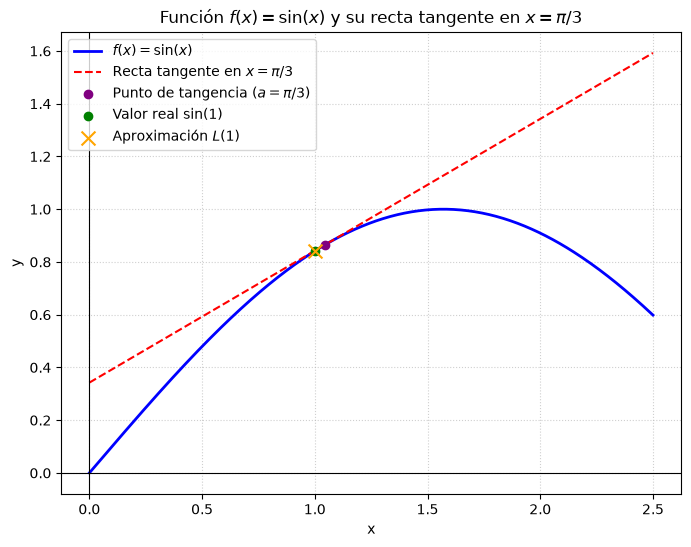

In [4]:
#TU CÓDIGO AQUÍ
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x_sym = sp.Symbol('x')
f_sym = sp.sin(x_sym)
a = sp.pi / 3

f_a = f_sym.subs(x_sym, a)
f_prime = sp.diff(f_sym, x_sym)
f_prime_a = f_prime.subs(x_sym, a)

# Recta tangente: y = f'(a)*(x - a) + f(a)
tangent_sym = f_prime_a * (x_sym - a) + f_a

print(f"Función: f(x) = sin(x)")
print(f"Punto de tangencia: a = pi/3")
print(f"Pendiente (f'(a)): {f_prime_a}")
print(f"Ecuación de la recta tangente: y = {tangent_sym}")

# Aproximación de sin(1)
val_aprox = tangent_sym.subs(x_sym, 1)
val_real = sp.sin(1)
error_relativo = sp.Abs(val_real - val_aprox) / val_real

print(f"\nAproximación de sin(1): {val_aprox.evalf():.6f}")
print(f"Valor real de sin(1): {val_real.evalf():.6f}")
print(f"Error relativo: {error_relativo.evalf():.6f} ({error_relativo.evalf() * 100:.4f}%)")

# --- 2. REPRESENTACIÓN GRÁFICA ---
x_vals = np.linspace(0, 2.5, 400)
f_num = np.sin(x_vals)
tangent_num = 0.5 * (x_vals - np.pi/3) + np.sqrt(3)/2

plt.figure(figsize=(8, 6))
plt.plot(x_vals, f_num, label='$f(x) = \\sin(x)$', color='blue', linewidth=2)
plt.plot(x_vals, tangent_num, label='Recta tangente en $x = \\pi/3$', color='red', linestyle='--')

# Marcar el punto de tangencia y el punto x = 1
plt.scatter([np.pi/3], [np.sin(np.pi/3)], color='purple', zorder=5, label='Punto de tangencia ($a = \\pi/3$)')
plt.scatter([1], [np.sin(1)], color='green', zorder=5, label='Valor real $\\sin(1)$')
plt.scatter([1], [float(val_aprox.evalf())], color='orange', marker='x', s=100, zorder=5, label='Aproximación $L(1)$')

plt.title('Función $f(x) = \\sin(x)$ y su recta tangente en $x = \\pi/3$')
plt.xlabel('x')
plt.ylabel('y')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Derivada por la izquierda en 0: 0
Derivada por la derecha en 0: 0
¡La derivada g'(0) existe y es igual a: 0!
x*sign(x) + Abs(x)


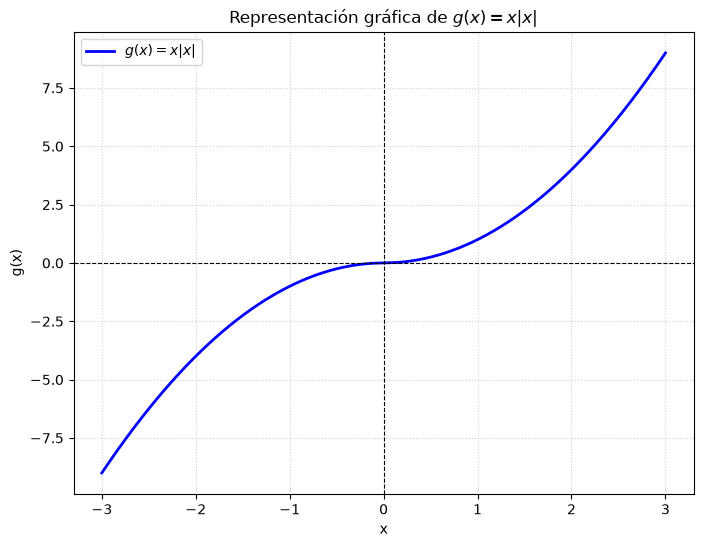

In [8]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x', real=True)
h = sp.Symbol('h', real=True)

# Definimos la función g(x) = x * |x|
g = sp.Lambda(x, x * sp.Abs(x))

# Derivada lateral por la izquierda en x = 0
der_izquierda = sp.limit((g(0 + h) - g(0)) / h, h, 0, dir='-')

# Derivada lateral por la derecha en x = 0
der_derecha = sp.limit((g(0 + h) - g(0)) / h, h, 0, dir='+')

print(f"Derivada por la izquierda en 0: {der_izquierda}")
print(f"Derivada por la derecha en 0: {der_derecha}")

if der_izquierda == der_derecha:
    print(f"¡La derivada g'(0) existe y es igual a: {der_izquierda}!")
else:
    print("La derivada g'(0) NO existe (las derivadas laterales son distintas).")

x_vals = np.linspace(-3, 3, 400)
g_vals = x_vals * np.abs(x_vals)

plt.figure(figsize=(8, 6))
plt.plot(x_vals, g_vals, label='$g(x) = x|x|$', color='blue', linewidth=2)

dg = sp.diff(g(x),x)
print(dg)
plt.title('Representación gráfica de $g(x) = x|x|$')
plt.xlabel('x')
plt.ylabel('g(x)')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Cálculo de extremos. Estudio de la monotonía de una función

Para calcular los extremos de una función real de una variable real, seguimos los pasos usuales.

A modo de ejemplo, vamos a calcular los extremos relativos de la función $f(x)=x^3-4x-3$. Como es derivable en todos sus puntos, calculamos en primer lugar los puntos en los que se anula su derivada:

In [ ]:
# Definimos la variable simbólica x
x = sp.Symbol('x',real=True) 
# Definimos la expresión simbólica f, que define la función
f = x**3 - 4*x - 3
# Calculamos la derivada de primer orden
df = sp.diff(f,x)
# Resolvemos la ecuación f'(x)=0 para determinar los POSIBLES extremos
a,b = sp.solve(df,x)
# Mostramos los POSIBLES extremos
display(a,b)

Evaluamos ahora la derivada segunda en los posibles extremos:

In [ ]:
# Calculamos la derivada de segundo orden
df2 = sp.diff(f,x,2)
# Evaluamos la derivada segunda en a y en b, y mostramos los valores
display(df2.subs(x,a)) 
display(df2.subs(x,b)) 

### Ejercicio 3: 

A la vista de los resultados, ¿son realmente extremos los puntos $a$ y $b$? En caso afirmativo, ¿qué tipo de extremos son? 

Representa gráficamente la función $f$ y sus extremos. 

In [ ]:
#TU CÓDIGO AQUÍ

### Ejercicio 4: 

Determina los extremos relativos y absolutos (si existen) de la función $f(x)=|x^2-16|$.

1. Escribe la función $f$ como una función definida a trozos.
2. Estudia la derivabilidad de la función $f$ en los puntos en los que cambia su definición.
3. Determina el conjunto de posibles extremos de la función $f$.
4. Estudia las propiedades de monotonía de la función $f$. ¿Tiene $f$ extremos relativos? En caso afirmativo, ¿son máximos o mínimos? ¿Tiene $f$ extremos absolutos?
5. ¿Tiene la función $f$ extremos absolutos en el intervalo $[-4,5]$? Justifica tu respuesta y, si es afirmativa, determina los extremos absolutos de $f$ en dicho intervalo.
6. Representa gráficamente la función, señalando en la gráfica sus extremos.

In [11]:
#TU CÓDIGO AQUÍ
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

x = sp.Symbol('x', real=True)
f = sp.(x**2-16)
plt.title('Representación gráfica de $g(x) = x^2-16')
plt.xlabel('x')
plt.ylabel('f(x)')
x = np.linspace(-2,6,50)
ytrozos = np.piecewise(x, [x<0, x>=0], [lambda x: -x, lambda x: np.sqrt(x)])
plt.figure()
plt.plot(x,ytrozos,label='ytrozos')

plt.title('Función a trozos')
plt.legend()
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

SyntaxError: invalid syntax (3241342333.py, line 7)

# Concavidad, convexidad y puntos de inflexión

Vamos a estudiar ahora la concavidad, convexidad y puntos de inflexión de una función dada usando **Python**. 

Consideramos de nuevo la función $f(x)=x^3-4x-3$. Como es dos veces derivable, calculamos su derivada segunda e igualamos a cero, para ver los posibles puntos de inflexión:

In [ ]:
# Definimos la variable simbólica x, real
x = sp.Symbol('x',real=True)
# Definimos la expresión simbólica f
f = x**3 - 4*x - 3
# Calculamos la derivada de segundo orden de f
df2 = sp.diff(f,x,2)
# Determinamos los POSIBLES puntos de inflexión, resolviendo la ecuación f''(x)=0
a = sp.solve(df2,x)
# Mostramos el posible punto de inflexión
display(a)

Evaluamos la derivada segunda en un punto de cada uno de los intervalos determinados por los puntos de inflexión, para ver el signo:

In [ ]:
display(df2.subs(x,-1)) # < 0 => f cóncava
display(df2.subs(x,1)) # > 0 => f convexa
# 0 es punto de inflexión

A la vista de los resultados, ¿qué se puede decir de la concavidad/convexidad de la función $f$? ¿Tiene la función $f$ algún punto de inflexión?

### Ejercicio 5:

Considera la función $$f(x)=\left\{\begin{array}{ll}
-x^2+1,& \text{si }x\leq -1,\\
\sin(\pi x), & \text{si }-1< x< 1,\\
e^{x^2}, & \text{si }1< x.
\end{array}\right.$$

Determina los intervalos en los que $f$ es cóncava y convexa. ¿Tiene la función $f$ algún punto de inflexión?

In [ ]:
#TU CÓDIGO AQUÍ